In [40]:


# pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics

# pip install tensorflow
import tensorflow as tf
import keras
from keras import layers

# encoders
from sklearn.preprocessing import LabelEncoder

# classification metrics
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score



In [41]:
df = pd.read_csv("Student_Depression_Dataset.csv")
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No


In [42]:
df.isna().sum()

# No NAs here

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [43]:
df.duplicated().sum()

# No duplicates

np.int64(0)

In [44]:
# Checking value_counts for the columns

for column in df.columns:
    values = df[column].value_counts()
    print(values)
    print()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

Age
23    1161
21     726
22     614
25     523
20     513
24     430
26     187
18      86
27      83
19      65
28      62
17      14
Name: count, dtype: int64

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

Current_semester
5     752
4     553
2     543
8     511
3     511
6     500
7     404
9     286
11    119
10    114
1      88
0      42
12     40
13      1
Name: count, dtype: int64

CGPA
3.00    280
3.60    142
3.50    135
4.00    130
3.89    130
       ... 
2.31      1
2.43      1
2.47      1
2.42      1
2.48      1
Name: count, Length: 169, dtype

In [45]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

## Cleaning the columns

In [46]:

varlist =  ['friend_circle', 'Depression']

# Defining the map function
def binary_map(x):
    return x.map({'Yes': 1, "No": 0})

# Applying the function
df[varlist] = df[varlist].apply(binary_map)

df["Gender"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

df['Living_style'] = df["Living_style"].map({
    "Bachelor": 0,
    "Family": 1
})

df["Family_background"] = df["Family_background"].map({
    "Lower Middle class": 0,
    "Middle class": 1,
    "Rich class": 2
})

df["Health_condition"] = df["Health_condition"].map({
    "Critical": 3,
    "Abnormal": 2,
    "Normal": 1,
    "Good": 0
})

In [47]:
# Get dummies for the nominal categories
df = pd.get_dummies(
    df,
    columns=["Home_division", "Marital_status", "Relationship_status"],
    drop_first=True,
    dtype=int
)

In [48]:
df.head(10)

# Quick sanity check that everything is OK. Looks to be ML-ready. :)

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,...,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single
0,1,22,1,0,8,3.43,1,3,10113,1,...,0,0,0,0,0,0,0,1,0,1
1,0,19,1,0,2,3.70,1,2,13815,1,...,0,0,0,0,0,0,0,1,0,1
2,0,23,1,1,8,3.28,0,2,15450,1,...,1,0,0,0,0,0,0,1,0,1
3,0,20,1,1,2,3.77,0,0,17413,0,...,1,0,0,0,0,0,0,1,0,0
4,1,21,1,1,1,4.00,0,2,16693,1,...,1,0,0,0,0,0,0,1,0,1
5,1,24,1,0,9,3.80,1,1,17244,0,...,0,0,0,0,0,0,0,1,0,1
6,1,21,0,1,9,3.50,1,1,1648,0,...,1,0,0,0,0,0,0,1,0,1
7,1,19,1,1,2,2.71,1,2,16782,1,...,0,0,0,1,0,0,0,1,0,1
8,1,21,1,1,3,3.10,1,2,13386,1,...,1,0,0,0,0,0,0,1,0,1
9,1,22,1,1,4,3.34,1,1,18131,0,...,0,0,1,0,0,0,0,0,1,0


In [49]:
df.dtypes
# All good

Gender                                     int64
Age                                        int64
Family_background                          int64
Living_style                               int64
Current_semester                           int64
CGPA                                     float64
friend_circle                              int64
Health_condition                           int64
Cost_without_study                         int64
Depression                                 int64
Home_division_Chittagong                   int64
Home_division_Dhaka                        int64
Home_division_Khulna                       int64
Home_division_Mymensingh                   int64
Home_division_Rajshahi                     int64
Home_division_Rangpur                      int64
Home_division_Sylhet                       int64
Marital_status_Separated                   int64
Marital_status_Unmarried                   int64
Relationship_status_In a Relationship      int64
Relationship_status_

## Quick EDA

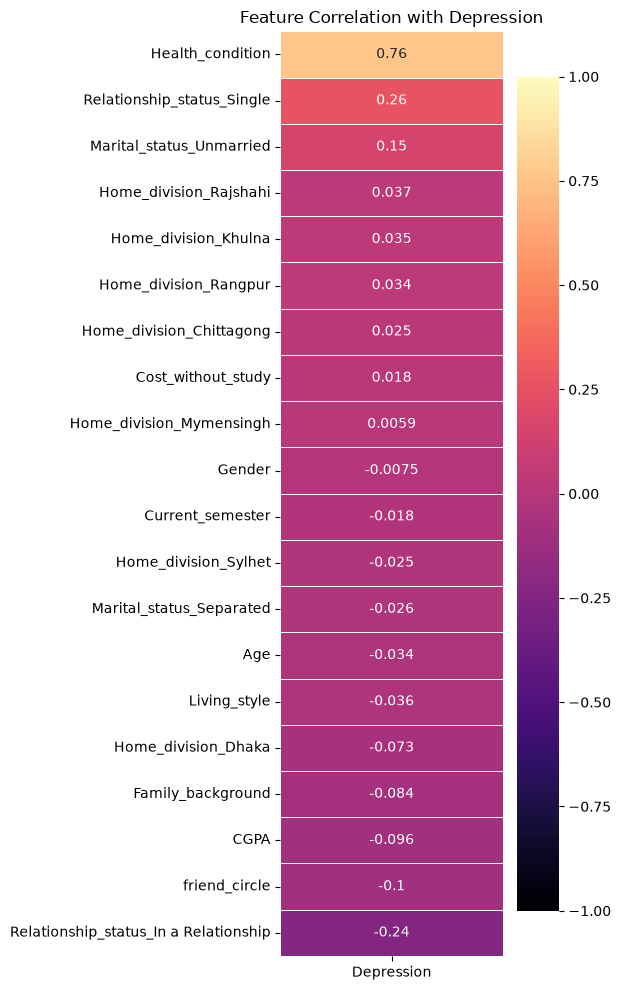

In [50]:
# Calculate correlations
corr = df.corr(numeric_only=True)["Depression"].drop("Depression")

# Sort descending
corr = corr.sort_values(ascending=False)

# Convert to DataFrame (single column)
corr_df = corr.to_frame()

# Plot
plt.figure(figsize=(6, 10))

sns.heatmap(
    corr_df,
    annot=True,
    cmap="magma",
    center=0,
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation with Depression")
plt.tight_layout()
plt.show()

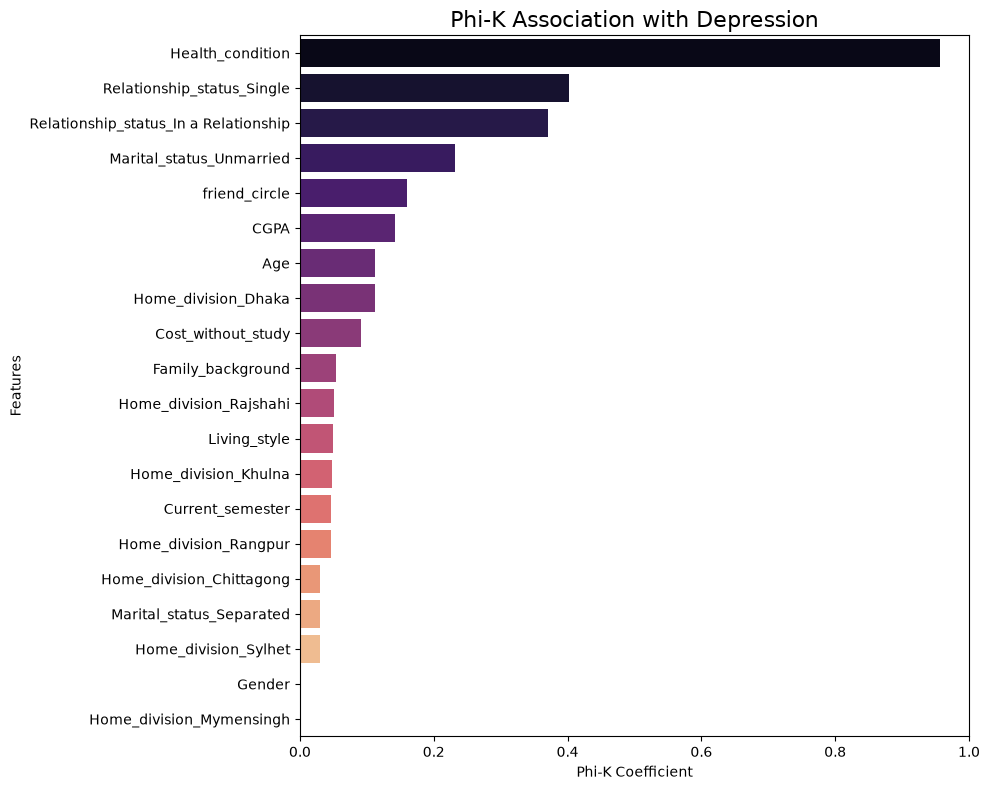

In [51]:
import phik
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Phi-K correlations
phik_corr = df.phik_matrix(
    interval_cols=df.select_dtypes(include="number").columns.tolist()
)

# Select Depression correlations
corr = phik_corr["Depression"].drop("Depression")
corr = corr.sort_values(ascending=False)

# Plot
plt.figure(figsize=(10, 8))

sns.barplot(
    x=corr.values,
    y=corr.index,
    hue=corr.index,
    palette="magma",
    legend=False
)

plt.title("Phi-K Association with Depression", fontsize=16)
plt.xlabel("Phi-K Coefficient")
plt.ylabel("Features")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

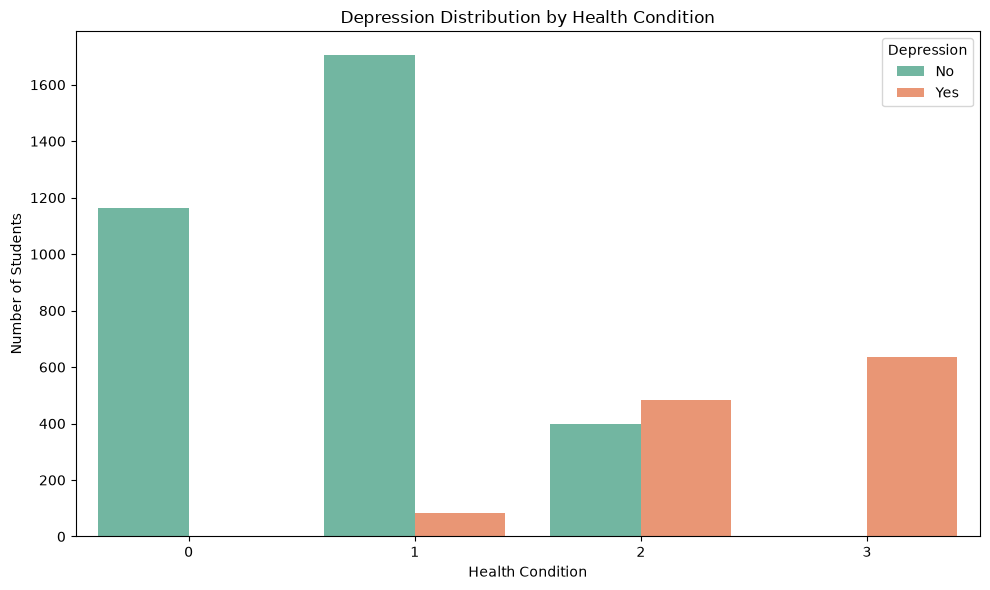

In [52]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Health_condition",
    hue="Depression",
    palette="Set2"
)

plt.title("Depression Distribution by Health Condition")
plt.xlabel("Health Condition")
plt.ylabel("Number of Students")
plt.legend(title="Depression", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

Makes sense. If your health is worse, you are more likely to be depressed.
These graphs are quick code from chatgpt, I wanted something more descriptive than basic heatmaps.

In [85]:
# this is technically completely optional
# but it's nicer to study the results when we have actual names for the output
# instead of just 0, 1, 2, 3 etc.

# let's assign actual names for the price classes
# so we have nicer metrics and results later (after training the model)
df['Depression'] = df['Depression'].replace({
    0: "No",
    1: "Yes"
})

## NN starts here

In [96]:

# perform X/y -split
# if you more than one independent variable, list them all here
# leave out the target variable (dependent variable)

# this is a nice and common trick => everything EXCEPT the target variable => support variables
X = df.drop("Depression", axis=1)

# have only the target variable here (dependent variable)
y_temp = df['Depression']

# since we are doing classification, we have to process our target values with an encoder
# and convert them into a categorical TensorFlow/Keras -format
le = LabelEncoder()
y_enc = le.fit_transform(y_temp)

# convert the label into matrix form
y = tf.keras.utils.to_categorical(y_enc)

# save the categories into a helper list for later purposes
categories = list(le.classes_)
categories



['No', 'Yes']

In [97]:
# in Classic ML, we only had train/test -split
# in deep learning, we usually use validation-data also, for better
# optimization possibilities and better metrics

# unfortunately the scikit-learn's train_test_split doesn't support validation
# set split in itself.

# if you want to split the test set into two for a validation set too, try this trick:

# step 1, split the data into 70% (training data) and 30% (temporary data)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.35)

# step 2, split the temporary data in HALF (0.5) => 15% test and 15% validation
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5)

In [98]:
# create neural network

# save the amount of support variables into a helper variable
# so we don't have to update the input_shape all the time
variable_amount = len(X.columns)

# Define Sequential neural network model
# input shape has to match the amount of SUPPORT VARIABLES
# in other words => amount of columns in X 
# Tip: have at least the same number of nodes as in the input shape

# output layer in classification depends on the amounts of
# unique output options in the target variable
model = keras.Sequential(
    [
        layers.BatchNormalization(input_shape=(variable_amount,)),
        layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l1(l1=0.1)),
        layers.Dense(8, activation="relu"),
        layers.Dense(2, activation="softmax")
    ]
)

# select the optimizer and loss function
# for classification, we use categorical crossentropy this time for loss-function
# we also wish to measure the accuracy of our model in the metrics
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

model.fit(x=X_train, y=y_train, epochs=30, validation_data=(X_val, y_val))

c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_dl\Lib\site-packages\keras\src\layers\normalization\batch_normalization.py:181: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization_12          │ (None, 20)             │            80 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 16)             │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 570 (2.23 KB)

 Trainable params: 530 (2.07 KB)

 Non-trainable params: 40 (160.00 B)

Epoch 1/30


91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7270 - loss: 5.8430 - val_accuracy: 0.7375 - val_loss: 4.5709
Epoch 2/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7297 - loss: 3.5676 - val_accuracy: 0.7375 - val_loss: 2.5901
Epoch 3/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step - accuracy: 0.7470 - loss: 1.8663 - val_accuracy: 0.8041 - val_loss: 1.1916
Epoch 4/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 983us/step - accuracy: 0.8504 - loss: 0.7854 - val_accuracy: 0.8822 - val_loss: 0.4868
Epoch 5/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step - accuracy: 0.8942 - loss: 0.4115 - val_accuracy: 0.9501 - val_loss: 0.3548
Epoch 6/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 962us/step - accuracy: 0.9093 - loss: 0.3483 - val_accuracy: 0.9577 - val_loss: 0.3154
Epoch 7/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step - accuracy: 0.9338 - loss: 0.3165 - val_accuracy: 0.9552 - val_loss: 0.2871
Epoch 8/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 928us/step - accuracy: 0.9369 - loss: 0.2928 - val_accuracy: 0.9629 - val_loss

<Axes: >

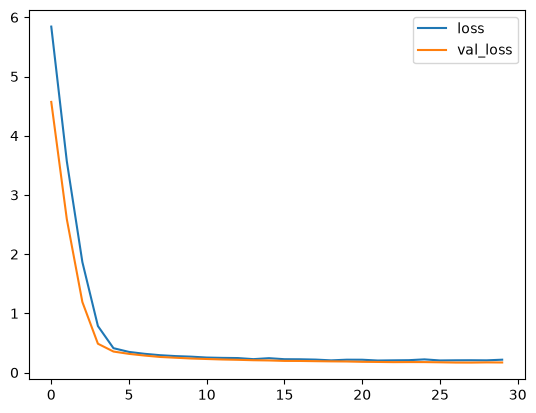

In [99]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

<Axes: >

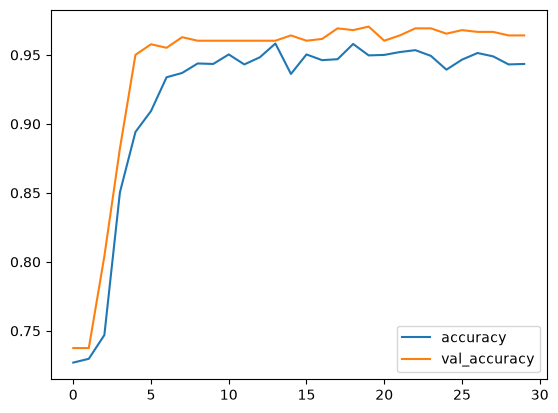

In [100]:
loss_df[['accuracy', 'val_accuracy']].plot()

In [101]:


# compare the final model loss/evaluation values
# the values should match roughly
print("Test data evaluation:")
print(model.evaluate(X_test, y_test, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(X_train, y_train, verbose=0))

# in classification we compare the loss and accuracy values



Test data evaluation:
[0.18080845475196838, 0.9616368412971497]

Train data evaluation:
[0.17749059200286865, 0.9596690535545349]


In [102]:
# get predictions and convert with argmax() to get the categories
# instead of RAW probabilites
test_predictions = model.predict(X_test)
test_predictions = np.argmax(test_predictions, axis=1)

# convert also y-test values with argmax
y_test = np.argmax(y_test, axis=1)



25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


<Axes: >

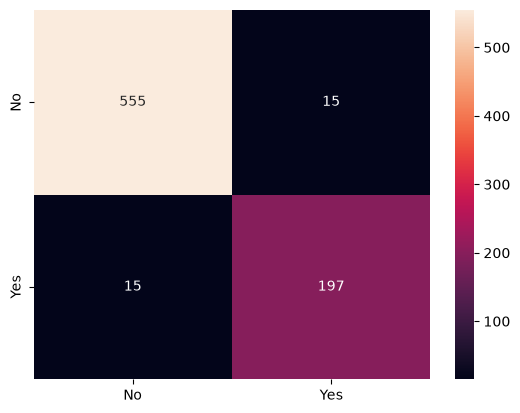

In [103]:
# confusion matrix
sns.heatmap(confusion_matrix(y_test, test_predictions), annot=True, fmt='g',
            xticklabels=categories, yticklabels=categories)



In [104]:
# print the classification report based on true values and predictions
print(classification_report(y_test, test_predictions, target_names=categories))

# get overall accuracy of the model and print it
acc = accuracy_score(y_test, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))



              precision    recall  f1-score   support

          No       0.97      0.97      0.97       570
         Yes       0.93      0.93      0.93       212

    accuracy                           0.96       782
   macro avg       0.95      0.95      0.95       782
weighted avg       0.96      0.96      0.96       782


Model overall accuracy: 96.16%


In [106]:
# The AUC score is a super sensitive metric
# you often get low scores, even 0.5

# in binary classification, AUC values are often interpreted as follows:
# A binary classifier is useful only when it achieves ROC-AUC score greater than 0.5 and as near to 1 as possible. 
# If a classifier yields a score less than 0.5, it simply means that the model is performing worse 
# than a random classifier, and therefore is useless.

# In multi category classification , AUC values are often interpreted as follows: 
# 0.5-0.6 (failed)
# 0.6-0.7 (worthless)
# 0.7-0.8 (poor)
# 0.8-0.9 (good)
# > 0.9 (excellent)

# get ROC-AUC -score
roc_auc_score(y, model.predict(X), multi_class="ovr")



140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 453us/step


0.9905602084073875

In [107]:

X.columns


Index(['Gender', 'Age', 'Family_background', 'Living_style',
       'Current_semester', 'CGPA', 'friend_circle', 'Health_condition',
       'Cost_without_study', 'Home_division_Chittagong', 'Home_division_Dhaka',
       'Home_division_Khulna', 'Home_division_Mymensingh',
       'Home_division_Rajshahi', 'Home_division_Rangpur',
       'Home_division_Sylhet', 'Marital_status_Separated',
       'Marital_status_Unmarried', 'Relationship_status_In a Relationship',
       'Relationship_status_Single'],
      dtype='str')

In [108]:
df.head(3)



,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,...,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_In a Relationship,Relationship_status_Single
0,1,22,1,0,8,3.43,1,3,10113,Yes,...,0,0,0,0,0,0,0,1,0,1
1,0,19,1,0,2,3.70,1,2,13815,Yes,...,0,0,0,0,0,0,0,1,0,1
2,0,23,1,1,8,3.28,0,2,15450,Yes,...,1,0,0,0,0,0,0,1,0,1


In [109]:
# let's try with some imaginary data
# modify this as needed regarding your own dataset

tester_row = {
    
}

# convert to pandas-format
tester_row = pd.DataFrame([tester_row])
result = model.predict(tester_row)[0]
result_text = categories[np.argmax(result)]

# switch to decimal representation 
np.set_printoptions(precision=9, suppress=True)

# 0 cheapest, 3 most expensive
print(f"Predicted depression: {result_text}")
print()
print("Probabilities by class:")
print(categories)
print(result)

ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'batch_normalization_12' is incompatible with the layer: expected axis -1 of input shape to have value 20, but received input with shape (1, 0)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(1, 0), dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>